# Portfolio Construction

## Project Statement

`spx_returns_weekly.xlsx` holds weekly returns on the current S&P 500 members from July 2015 to June 2026. A two-year estimation window has 104 weeks; 457 of the names have complete histories. The sample covariance of 457 names from 104 weeks is singular, so the mean-variance machinery cannot be applied as written.

Build a covariance model that survives being used to choose a portfolio. Use it to construct a book of these names, and measure out of sample whether the book delivers the risk it promised.


## Context

The tangency portfolio is proportional to $\Sigma^{-1}\tilde\mu$; the global minimum-variance (GMV) portfolio is proportional to $\Sigma^{-1}\mathbf{1}$. A sample covariance from $T$ observations on $N$ assets has rank at most $\min(T-1,N)$.

Sector-factor models and regularization provide alternative covariance estimates. Their performance can differ between fixed portfolios and portfolios chosen using the same estimates. Both comparisons are required below.


## Data

| File | Contents | Frequency | Dates |
|---|---|---|---|
| `data/spx_returns_weekly.xlsx` | `spx returns`: total returns on 503 current S&P 500 members; `spx names`: name, GICS sector, market capitalization; `sector returns`: eleven sector ETFs; `additional returns`: SPY, IEF, IYR, GLD, USO, bitcoin, SHV; `rates returns`: the 3-month Treasury bill yield | weekly, Friday close | 2015-07-10 to 2026-06-26 (573 weeks) |
| `data/spx_returns_daily_full.parquet` | daily total returns on 503 current S&P 500 members | daily | 2016-06-24 to 2026-06-22 (2,511 days) |
| `data/sector_etf_data_daily.xlsx` | prices, total returns and excess returns on the eleven sector ETFs | daily | 2000-01-04 to 2026-06-29 |

#### Notes

- The `rates returns` sheet is the annualized yield level of the 3-month bill (`USGG3M`), as a decimal. Divide by 52 for the weekly risk-free rate; SHV's weekly return in `additional returns` is a check on that conversion. No daily bill series ships.
- The `excess returns` sheet of the sector workbook subtracts the daily change in SHV's price (SHV is a column of its `prices` sheet): a basis point or two on most days and about 40 basis points on SHV's monthly ex-dividend day, averaging near zero over a month. It is not a bill rate. Section 5 works in total returns.
- Forty-six names have missing values at the start of the weekly panel because they listed after July 2015; the remaining 457 have complete histories. The panel is the index membership when the workbook was built, with each member's history filled backward, so it holds the names that survived into the index.
- `mkt cap` in `spx names` is a single snapshot taken when the workbook was built in July 2026 (Bloomberg `CUR_MKT_CAP`); it carries no history. The two Alphabet share classes (`GOOG`, `GOOGL`) and the two News Corp classes (`NWS`, `NWSA`) each carry the whole company's capitalization.
- The sector ETF `XLRE` begins in October 2015 and `XLC` in June 2018.
- Daily tickers use a hyphen where weekly tickers use a slash (`BRK-B` and `BRK/B`). The two panels' memberships differ slightly: of the 457 names, `ECHO`, `FLEX` and `MRVL` are absent from the daily panel and `FISV` has no daily return on 2025-11-12 and 2025-11-13. Section 5 drops all four and runs on 453 names.
- Annualize weekly statistics with 52 and daily statistics with 252.


#### Conventions

Unless a question says otherwise:

| Item | Convention |
|---|---|
| universe | the 457 names with complete weekly histories |
| returns | weekly excess returns over the 3-month bill |
| estimation window | the trailing 104 weeks |
| rebalance | every 4 weeks; the weights apply unchanged to each weekly return of the holding period, which is weekly rebalancing to target rather than drift |
| first estimation date | 2017-10-06, the first Friday whose trailing 104 weeks contain all ten sector ETFs other than `XLC`; the out-of-sample period is 2017-10-13 to 2026-06-26 |
| factors | the ten sector ETFs other than `XLC`, in excess returns |
| GMV | weights sum to one |
| tangency | the direction $\Sigma^{-1}\tilde\mu$, scaled so the ex-ante annualized volatility under the covariance used is 10% |
| portfolio metrics | the list below |
| realized variance | the sample variance of the return sequence about its own mean with $n - 1$ in the denominator (`ddof=1`, the pandas default); realized volatility is its square root, annualized |
| benchmarks | equal weight of the 457 names, rebalanced every 4 weeks, and SPY |


**Portfolio metrics** (called *book metrics* below):

- Annualized mean, volatility, and Sharpe ratio of excess returns.
- Maximum drawdown of compounded total returns (excess returns plus the bill).
- Average gross and net exposure, and number of positions.
- Annual one-way turnover: $\frac{52}{4}\frac12\sum_i|w_{i,t}-w_{i,t-1}|$, averaged over rebalances after the first.
- Predicted annualized volatility, averaged over rebalances, and realized annualized volatility.


## Data Preview


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4.5)
plt.rcParams['font.size'] = 12

from pathlib import Path

DATA_DIR = Path('data')  # 'data' folder living alongside this notebook
WEEKLY = DATA_DIR / 'spx_returns_weekly.xlsx'
DAILY = DATA_DIR / 'spx_returns_daily_full.parquet'     # Section 5
SECTOR_DAILY = DATA_DIR / 'sector_etf_data_daily.xlsx'  # Section 5
FREQ = 52

xl = pd.ExcelFile(WEEKLY)
names = xl.parse('spx names').set_index('ticker')
rets = xl.parse('spx returns').set_index('date')
sectors = xl.parse('sector returns').set_index('date')
other = xl.parse('additional returns').set_index('date')
rf = xl.parse('rates returns').set_index('date').iloc[:, 0] / FREQ        # annualized yield level -> weekly rate

complete = rets.columns[rets.notna().all()]
retsx = rets[complete].sub(rf, axis=0)                                    # weekly excess returns, 457 names
spyx = other['SPY'] - rf

print(f'{rets.shape[0]} weeks, {rets.index[0].date()} to {rets.index[-1].date()}; {rets.shape[1]} names, {len(complete)} with complete histories')
print(f'weekly risk-free rate, annualized mean: {rf.mean() * FREQ:.2%};  SHV weekly return, annualized mean: {other["SHV"].mean() * FREQ:.2%}')

573 weeks, 2015-07-10 to 2026-06-26; 503 names, 457 with complete histories
weekly risk-free rate, annualized mean: 2.17%;  SHV weekly return, annualized mean: 2.03%


In [ ]:
sector_table = pd.DataFrame({
    'names': names['gics_sector_name'].value_counts(),
    'complete histories': names.loc[complete, 'gics_sector_name'].value_counts(),
    'cap share of snapshot': names.groupby('gics_sector_name')['mkt cap'].sum() / names['mkt cap'].sum(),
}).fillna(0)
sector_table.index.name = 'GICS sector'
sector_table.style.format({'names': '{:.0f}', 'complete histories': '{:.0f}', 'cap share of snapshot': '{:.1%}'}, na_rep='-')

,names,complete histories,cap share of snapshot
GICS sector,,,
Communication Services,23,18,16.1%
Consumer Discretionary,47,44,9.2%
Consumer Staples,34,32,4.7%
Energy,21,20,2.8%
Financials,76,72,11.8%
Health Care,59,56,8.2%
Industrials,81,70,7.9%
Information Technology,74,65,34.0%
Materials,26,22,1.6%


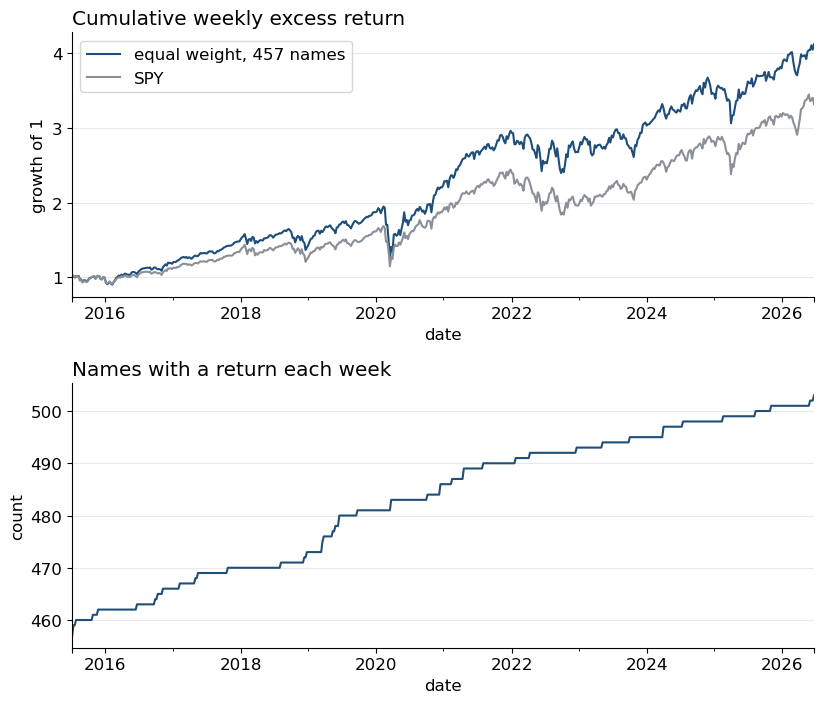

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(8.4, 7.2))
ew = retsx.mean(axis=1)
(1 + pd.DataFrame({'equal weight, 457 names': ew, 'SPY': spyx})).cumprod().plot(ax=ax[0], color=['#1f4e79', '#8a8f98'], lw=1.5)
ax[0].set_title('Cumulative weekly excess return', loc='left'); ax[0].set_ylabel('growth of 1'); ax[0].grid(axis='y', color='#e6e8eb')
rets.notna().sum(axis=1).plot(ax=ax[1], color='#1f4e79', lw=1.5)
ax[1].set_title('Names with a return each week', loc='left'); ax[1].set_ylabel('count'); ax[1].grid(axis='y', color='#e6e8eb')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()


***


# 1. The Failure, Given

Take the 104 weeks ending 2025-12-26, the last week followed by 26 weeks of data. This window is used once; it is not a rebalance date of the later sections.


## 1.1

Estimate the sample covariance of the 457 names over this window. Compute the GMV weights with `np.linalg.inv` (or `solve`) and again with `np.linalg.pinv`. Report

* the rank and condition number of the covariance
* for each inverse: the in-sample annualized volatility, the gross exposure, the largest absolute weight, and the realized annualized volatility over the 26 weeks that follow


## 1.2

Explain what each inverse computed, why the two in-sample volatilities differ, and what the pseudo-inverse assumes about the directions the sample did not measure.


***


# 2. Build and Validate the Covariance


## 2.1

Over the same window, regress each name's excess return on the ten sector ETFs and build the factor covariance $\Sigma_F$ with a diagonal residual matrix. Report

* the quartiles of $R^2$ across names
* the average pairwise correlation within sectors and across sectors, for the returns and for the residuals
* the rank and condition number of $\Sigma_F$
* $\Sigma_F$ rebuilt with the full residual covariance in place of the diagonal, compared with the sample covariance of 1.1, and what you find

#### Factor Covariance

With $r_{i,t} = \alpha_i + \boldsymbol{\beta}_i' \boldsymbol{f}_t + \epsilon_{i,t}$ on $k$ factors, loadings $\boldsymbol{B}$ ($k \times N$), factor covariance $\Sigma_f$ and residual variances on the diagonal of $\boldsymbol{D}$, the factor covariance is $\Sigma_F = \boldsymbol{B}'\,\Sigma_f\, \boldsymbol{B} + \boldsymbol{D}$. The residual treatment is a choice: a diagonal $\boldsymbol{D}$, residual covariance kept within sectors, or the full residual covariance.


## 2.2

Run the forecast test. On every rebalance date followed by 26 weeks of data (2017-10-06 through 2025-12-19), estimate three covariances from the trailing 104 weeks: the sample covariance, the diagonal matrix of sample variances, and $\Sigma_F$ with diagonal residuals. Fix these test portfolios of the 457 names:

* equal weight
* 100 random long-short portfolios with each weight drawn from $\pm 1/N$ (state your seed)
* 100 same-sector pair spreads, long one name and short another in the same sector
* the 55 spreads between pairs of GICS sectors, long one sector's equal-weight portfolio and short the other's
* a fifth type, chosen rather than fixed: the GMV each estimator produces on the same window (through the pseudo-inverse where the estimator is singular), with its variance forecast by that estimator

For each date, estimator and portfolio, compute the log of the realized variance over the following 26 weeks divided by the predicted variance. Report, by estimator and portfolio type, the mean of that log ratio and its root mean square.


## 2.3

For which portfolio types is each estimator's mean log variance ratio close to zero? Relate the errors to variance estimates, within-sector residual correlation, and factor loadings. Compare each estimator's record on the fixed portfolios with its record on its own GMV, and say what the sample covariance's record on fixed portfolios implies about the source of the result in 1.1.


## 2.4

Change one element of the factor model and rerun 2.2 with the result as a fourth estimator. Choose one change: the factor set (market only; market plus sectors; or eleven sectors, which shortens the sample to windows starting June 2018 or later), the residual treatment (residual covariance kept within sectors), or the window length.

* State the change and show the new estimator beside the three of 2.2 in the same table.
* Name the covariance you will carry into Sections 3 to 5 and 7, and the reason for choosing it over the alternative you tested. If Section 3 changes your mind, say so there and say why.


***


# 3. Minimum Variance


## 3.1

Over the out-of-sample period, report the book metrics for the two benchmarks and for a third: the capitalization-weighted portfolio built from the `mkt cap` snapshot, rebalanced to those weights every 4 weeks.

The snapshot was taken at the end of the sample. What does that do to a backtest that starts in 2017, how do the share-class double counts enter, and which of the three portfolios could a 2017 investor have held?


## 3.2

On the rolling protocol, build the GMV under three covariances: the sample covariance through the pseudo-inverse, your factor covariance from 2.4, and one stabilization of the sample covariance that you choose and state: ridge with a rule for $\lambda$, shrinkage toward the diagonal, Ledoit-Wolf, or a penalized regression.

* Report the book metrics for each, including predicted and realized volatility.
* Plot cumulative returns and gross exposure through time against the benchmarks.


## 3.3

Build the long-only GMV under your factor covariance with NNLS in the regression form. Report the same metrics.

#### NNLS Formulation

For the long-only tangency portfolio, NNLS of a constant on the return panel gives the weights, as in *MV Optimization via Regression*. For the GMV under any covariance $\Sigma = \boldsymbol{L}\boldsymbol{L}'$ (a Cholesky or eigenvalue factor), the variance is $\lVert \boldsymbol{L}'\boldsymbol{w} \rVert^2$. Stack the rows of $\boldsymbol{L}'$ with one additional row $\kappa\,\mathbf{1}'$ and a target vector of zeros with a final entry $\kappa$: the least-squares objective becomes $\boldsymbol{w}'\Sigma\boldsymbol{w} + \kappa^2(1 - \mathbf{1}'\boldsymbol{w})^2$. With $\kappa$ large relative to the return scale, NNLS on that system gives the long-only GMV up to a rescaling of the weights to sum to one.


## 3.4

Compare the portfolios in 3.2 and 3.3.

- Which covariance produced the lowest realized volatility? How does realized volatility compare with predicted volatility?
- How did stabilization affect gross exposure, turnover, and concentration? In which years did it perform worst?
- What changed under the long-only constraint? Explain the result.


***


# 4. The Mean Input


## 4.1

Build the tangency portfolio under your factor covariance with three return inputs: the sample means of the window; the sample means shrunk halfway toward the grand mean, $a = 0.5$; and the CAPM-implied means, $\beta_i$ times the window's mean market excess return, with $\beta_i$ estimated on SPY over the window. Scale each to 10% ex-ante volatility.

* Report the book metrics, including predicted and realized volatility.
* State what the $a = 1$ book is without running it.

#### Mean Shrinkage

Shrinkage toward the grand mean across names with weight $a$: $\tilde{\mu}_i^{(a)} = (1-a)\,\hat{\tilde\mu}_i + a\,\bar{\hat{\tilde\mu}}$.


## 4.2

Compute the standard error of a 104-week annualized mean for a name of typical volatility and compare it with the cross-sectional standard deviation of the window's annualized means. Use the two components of $\Sigma^{-1}\tilde\mu$ under each anchor to explain how the books in 4.1 change with $a$. Derive the tangency weights when the return input is the CAPM-implied mean and the covariance is a single-factor model with diagonal residuals, and say which kinds of names such a book favors.


***


# 5. The Book's Own Risk

Switch to daily data. Weights in force on a trading day are those of the most recent weekly rebalance. Map tickers between the two panels; drop `ECHO`, `FLEX`, `MRVL` and `FISV`, leaving 453 names, and rescale the remaining weights to the sum they had before the drop. The daily panel holds total returns and no daily bill series ships, so each book's daily return is its total return, and every VaR forecast and hit test is on that total return.


## 5.1

Carry forward one book from Section 3 or 4 and name it; keep equal weight as the control. For each trading day from the first rebalance date, forecast the next day's 5% VaR of each book from the trailing 252 trading days, three ways:

* the historical quantile of the book's return with current weights
* normal VaR with your factor covariance fit on the daily sector returns from the `total returns` sheet
* EWMA with $\lambda = 0.94$ on the book's daily return with current weights


## 5.2

Run the hit test for each book and forecast over the full period and within these windows: 2020-02-19 to 2020-04-30; calendar 2022; calendar 2023. Report

* the breach rate in each cell and the number of days in each window
* for the historical and factor-normal forecasts, the realized conditional VaR on the breach days against the CVaR the forecast implies


## 5.3

Which forecasts miss their target breach rate, for which portfolio, and through which estimated risk quantity? What does sharing one window between the choice of weights and the estimate of their risk do to the historical quantile? What can the number of days in each regime window establish, and what can it not?


***


# 6. Pricing the Names


## 6.1

Over the full weekly sample, estimate each of the 457 names' beta on SPY and run these two tests of the CAPM:

* Regress the names' mean excess returns on their betas. Report the slope and intercept beside the sample market premium.
* Run the joint test of zero alphas from the DFA case on the ten sector ETFs against SPY. Report the statistic, $p$-value, $T$, $N$ and degrees of freedom.


## 6.2

Interpret the two tests together. Compare the cross-sectional slope with the market premium and with the pattern in *CAPM on 49 Industry Portfolios*; if they differ, name a feature of this panel that could produce the difference. What do the CAPM-implied means of 4.1 assume, and how does this evidence bear on that choice of return input?


***


# 7. Build Your Book

Choose a portfolio using the evidence above. The covariance model, return input, constraints, and objective are decisions to justify; a higher realized Sharpe ratio alone does not establish a better design.


## 7.1

Before testing, declare in one table:

* the universe: the 457 static names, the full panel with membership changing as histories begin, or a subset
* the covariance and any stabilization, and the mean treatment, or none
* the constraints: long-only, position caps, a gross limit, sector neutrality
* the objective: variance, or a tail measure if you bring a solver
* the window length, rebalance frequency and a one-way cost per unit turnover in basis points
* the evaluation rule, which must include the ratio of realized to predicted volatility and the VaR breach rate of the book, alongside whatever return metrics you choose against the two benchmarks

Use the declared rule to evaluate the portfolio. The design is informed by Sections 2 to 6; although each rolling estimate uses past data, the overall design has not been tested on an untouched sample.


## 7.2

Build the book on the rolling protocol with your window and rebalance frequency and report it under your rule. Then change one thing, the window length or the universe, and report what changed.


## 7.3

For each choice in 7.1, name the alternative you rejected and the evidence from Sections 2 to 6 that decided it. Close with what your evidence supports and what this sample cannot establish.


***


## Deliverables

Follow the [Project Guidelines](11.0.%20Project%20Guidelines.md).
